In [1]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

# Transformations
transform = transforms.Compose([
    transforms.Pad(2),          # 28x28 -> 32x32
    transforms.ToTensor()       # convertit en tenseur et met les pixels entre 0 et 1
])

# Dataset Fashion MNIST
full_train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Split train / validation
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

# DataLoaders
batch_size = 128

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Train size :", len(train_dataset))
print("Val size   :", len(val_dataset))
print("Test size  :", len(test_dataset))

Device : cpu
Train size : 48000
Val size   : 12000
Test size  : 10000


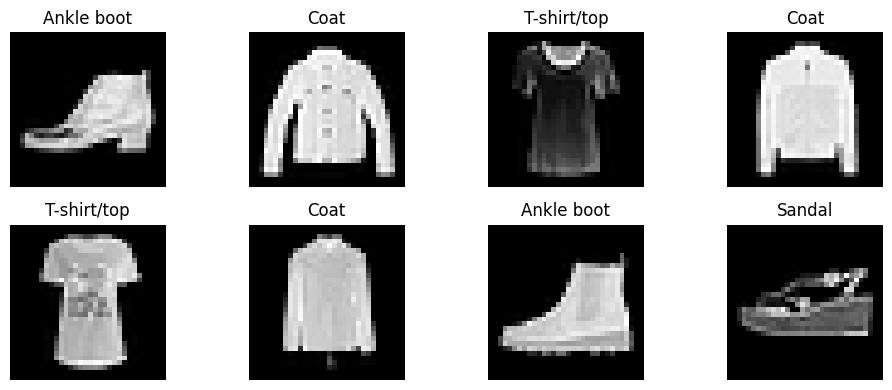

Shape d'une image : torch.Size([1, 32, 32])


In [2]:
class_labels = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Visualisation de quelques exemples
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(class_labels[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Shape d'une image :", images[0].shape)

In [3]:
import torch
import torch.nn as nn

class VAE(nn.Module):
    def __init__(self, input_shape=(1, 32, 32), latent_dim=2):
        """
        Variational Autoencoder initialization.

        Args:
            input_shape (tuple): Shape of the input image. Default is (1, 32, 32).
            latent_dim (int): Dimension of the latent representation.
        """
        super(VAE, self).__init__()

        # ------------------
        # 1. Encoder
        # ------------------
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),   # 32x32 -> 16x16
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),  # 16x16 -> 8x8
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1), # 8x8 -> 4x4
            nn.ReLU()
        )

        # Taille après l'encodeur
        flattened_size, decode_shape = self.calculate_flattened_size(self.encoder, input_shape)
        self.decode_shape = decode_shape  # utile pour reshaper dans le décodeur

        # ------------------------------------------------
        # 2. Fully Connected Layers for Latent Space
        # ------------------------------------------------
        self.fc_mu = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(flattened_size, latent_dim)
        )

        self.fc_logvar = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(flattened_size, latent_dim)
        )

        # ------------------
        # 3. Decoder
        # ------------------
        self.decoder_input = nn.Linear(latent_dim, flattened_size)

        self.decoder = nn.Sequential(
            nn.Unflatten(dim=1, unflattened_size=decode_shape[1:]),

            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),  # 4x4 -> 8x8
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),   # 8x8 -> 16x16
            nn.ReLU(),

            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1),    # 16x16 -> 32x32
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        """
        Reparameterization trick:
        z = mu + sigma * eps, where eps ~ N(0, I)
        """
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def calculate_flattened_size(self, model, input_shape):
        with torch.no_grad():
            dummy_input = torch.zeros(1, *input_shape)
            output = model(dummy_input)
        return output.numel(), output.shape

    def forward(self, x):
        """
        Forward pass for the VAE.
        """
        x_encoded = self.encoder(x)

        mu = self.fc_mu(x_encoded)
        logvar = self.fc_logvar(x_encoded)

        z = self.reparameterize(mu, logvar)

        recon_x = self.decoder_input(z)
        recon_x = self.decoder(recon_x)

        return recon_x, mu, logvar, z

In [4]:
x_sample = torch.randn(1, 1, 32, 32)
model_test = VAE()
image_test, mu, logvar, z = model_test(x_sample)

print("Image reconstruite :", image_test.shape)
print("mu :", mu.shape)
print("logvar :", logvar.shape)
print("z :", z.shape)

assert image_test.shape == x_sample.shape, "Output dimensions do not match input dimensions!"

Image reconstruite : torch.Size([1, 1, 32, 32])
mu : torch.Size([1, 2])
logvar : torch.Size([1, 2])
z : torch.Size([1, 2])


In [5]:
import torch.nn.functional as F

def vae_loss(recon_x, x, mu, logvar, beta=1):
    """
    Compute the Variational Autoencoder (VAE) loss function.
    """
    # 1) Reconstruction Loss
    recon_loss = F.binary_cross_entropy(recon_x, x, reduction='sum')

    # 2) KL Divergence
    kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    # Total loss
    return recon_loss + beta * kl_div

In [6]:
from tqdm import tqdm
import matplotlib.pyplot as plt

def evaluate_model(model, loader, beta=1):
    """
    Evaluates the VAE on a validation or test dataset.
    """
    model.eval()
    total_loss = 0
    ce_loss_placeholder = 0

    with torch.no_grad():
        for x, _ in tqdm(loader, desc="Evaluating"):
            x = x.to(device)

            recon_x, mu, logvar, _ = model(x)

            loss = vae_loss(recon_x, x, mu, logvar, beta=beta)
            total_loss += loss.item()

    avg_loss = total_loss / len(loader.dataset)
    return avg_loss, ce_loss_placeholder

In [7]:
def plot_training_loss(train_losses, val_losses):
    plt.figure(figsize=(8, 5))
    plt.plot(train_losses, label="Training Loss", marker="o")
    plt.plot(val_losses, label="Validation Loss", marker="s")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid()
    plt.show()

In [8]:
def train_model(model, train_loader, val_loader, epochs, beta=1):
    """
    Trains a VAE model with a given β for the KL term.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        tqdm_loader = tqdm(train_loader, desc=f"Training Epoch {epoch + 1}/{epochs}")

        for x, _ in tqdm_loader:
            # 1) Reset gradients
            optimizer.zero_grad()

            # 2) Move batch to device
            x = x.to(device)

            # 3) Forward pass
            recon_x, mu, logvar, _ = model(x)

            # 4) Compute loss
            loss = vae_loss(recon_x, x, mu, logvar, beta=beta)

            # 5) Backpropagation
            loss.backward()

            # 6) Update weights
            optimizer.step()

            total_loss += loss.item()
            tqdm_loader.set_postfix(loss=loss.item())

        avg_train_loss = total_loss / len(train_loader.dataset)

        avg_val_loss, _ = evaluate_model(model, val_loader, beta=beta)

        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Train Loss: {avg_train_loss:.4f}, "
            f"Val Loss: {avg_val_loss:.4f}"
        )

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)

    plot_training_loss(train_losses, val_losses)

Training VAE...


Evaluating: 100%|██████████| 94/94 [00:04<00:00, 21.18it/s]


Epoch [1/10], Train Loss: 429.0994, Val Loss: 329.3294


Evaluating: 100%|██████████| 94/94 [00:04<00:00, 20.65it/s]


Epoch [2/10], Train Loss: 310.7746, Val Loss: 299.7765


...

Epoch [8/10], Train Loss: 276.2187, Val Loss: 275.6721


Evaluating: 100%|██████████| 94/94 [00:04<00:00, 23.31it/s]


Epoch [9/10], Train Loss: 274.8444, Val Loss: 274.3583


Evaluating: 100%|██████████| 94/94 [00:05<00:00, 15.70it/s]


Epoch [10/10], Train Loss: 273.6836, Val Loss: 273.2422


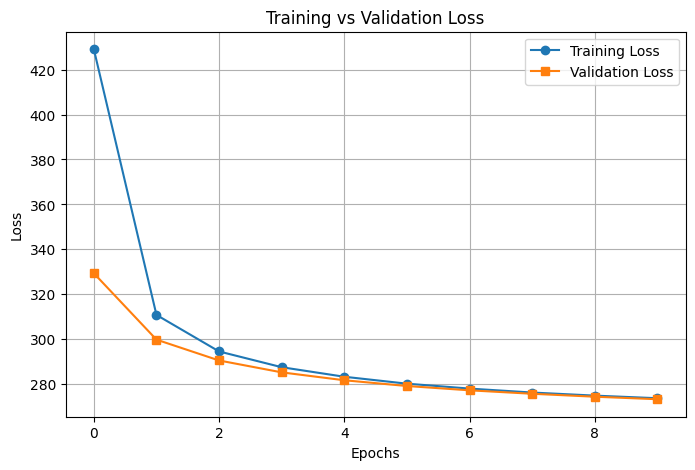

In [9]:
vae = VAE().to(device)
print("Training VAE...")
train_model(vae, train_loader, val_loader, epochs=10, beta=1)

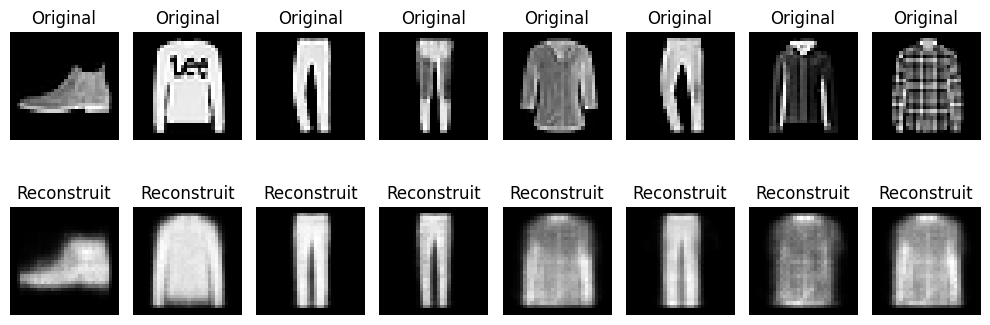

In [13]:
def show_reconstructions(model, loader, n=8):
    model.eval()

    with torch.no_grad():
        x, _ = next(iter(loader))
        x = x.to(device)

        recon_x, _, _, _ = model(x)

    x = x.cpu()
    recon_x = recon_x.cpu()

    plt.figure(figsize=(10, 4))

    for i in range(n):
        # Image originale
        plt.subplot(2, n, i + 1)
        plt.imshow(x[i].squeeze(), cmap="gray")
        plt.title("Original")
        plt.axis("off")

        # Image reconstruite
        plt.subplot(2, n, i + 1 + n)
        plt.imshow(recon_x[i].squeeze(), cmap="gray")
        plt.title("Reconstruit")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

show_reconstructions(vae, test_loader)

In [14]:
def plot_latent_space(model, loader):
    model.eval()

    all_mu = []
    all_labels = []

    with torch.no_grad():
        for x, labels in loader:
            x = x.to(device)

            _, mu, _, _ = model(x)

            all_mu.append(mu.cpu())
            all_labels.append(labels)

    all_mu = torch.cat(all_mu, dim=0)
    all_labels = torch.cat(all_labels, dim=0)

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        all_mu[:, 0],
        all_mu[:, 1],
        c=all_labels,
        cmap="tab10",
        s=5
    )

    plt.colorbar(scatter)
    plt.title("Latent Space Representation (mu)")
    plt.xlabel("z1")
    plt.ylabel("z2")
    plt.show()

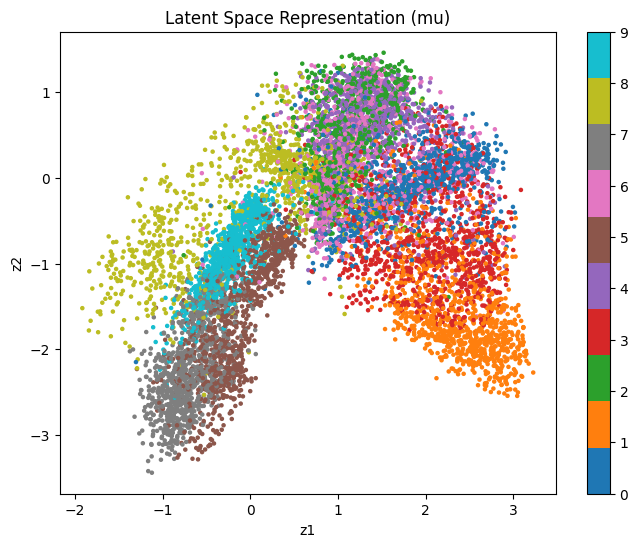

In [15]:
plot_latent_space(vae, test_loader)

In [16]:
def generate_images(model, n=10):
    model.eval()

    with torch.no_grad():
        # Générer des points aléatoires dans l’espace latent
        z = torch.randn(n, 2).to(device)

        # Passer dans le décodeur
        generated = model.decoder_input(z)
        generated = model.decoder(generated)

    generated = generated.cpu()

    plt.figure(figsize=(10, 2))

    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(generated[i].squeeze(), cmap="gray")
        plt.axis("off")

    plt.suptitle("Images générées")
    plt.show()

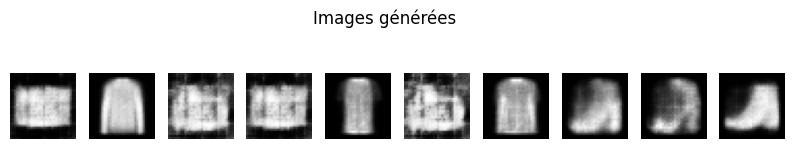

In [17]:
generate_images(vae, n=10)

In [18]:
def generate_grid(model, n=10, range_lim=3):
    model.eval()

    grid_x = torch.linspace(-range_lim, range_lim, n)
    grid_y = torch.linspace(-range_lim, range_lim, n)

    images = []

    with torch.no_grad():
        for yi in grid_y:
            row = []
            for xi in grid_x:
                z = torch.tensor([[xi, yi]]).float().to(device)
                img = model.decoder_input(z)
                img = model.decoder(img)
                row.append(img.cpu())
            images.append(row)

    plt.figure(figsize=(8, 8))

    for i in range(n):
        for j in range(n):
            plt.subplot(n, n, i * n + j + 1)
            plt.imshow(images[i][j].squeeze(), cmap="gray")
            plt.axis("off")

    plt.suptitle("Exploration de l’espace latent")
    plt.show()

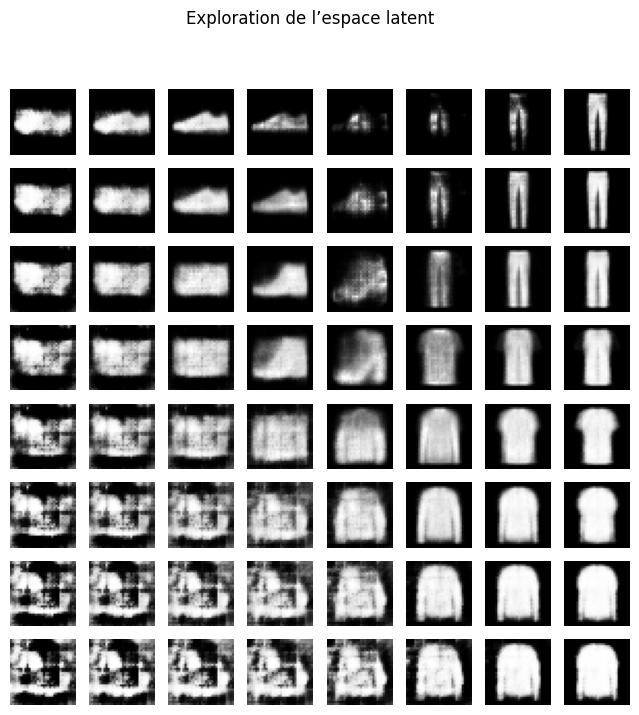

In [19]:
generate_grid(vae, n=8)